# 12 — Stealing-Guided Synonym Substitution | V1 Final

**Project:** Break the Watermark! · Trustworthy AI seminar  
**Status:** consolidated **exploratory** V1, not an independent test-set confirmation.

### Questions
1. Does a learned position-ranking strategy outperform random eligible positions at *matched actual word-edit counts*?
2. Do WM/NoWM word-frequency statistics help select synonyms, or is random WordNet substitution better?
3. Is ranking by **original word WM score** better than ranking by **best achievable score gain**?
4. How do `MIN_SUPPORT`, vocabulary coverage, and nominal vs actual edit budget change outcomes?

**What this notebook does:** explains and implements V1; verifies and summarizes saved experiment outputs from notebooks 10 and 11; runs paired exact McNemar tests with Holm correction on **one reference split**; describes variation over all 10 overlapping splits. **It does not rerun LLaDA, regenerate outputs, or recalculate watermark detection**. Its statistical results cannot be calculated from aggregate ASRs alone: it reads the previously saved **per-text** paired outcomes.

**Scope:** watermark detection / removal ASR only. Semantic-preservation quality is **not** measured here. A successful attack according to the detector is not necessarily meaning-preserving.

## 1. Environment and input provenance

Run from anywhere inside the existing project tree. Expected artifacts are generated by `10_stealing_guided_v1_support_2_5_10_15.ipynb` and `11_stealing_guided_position_selection.ipynb`. No GPU or 8B model is required. Dependencies: `pandas`, `numpy`, `scipy`, `IPython`; `nltk`/WordNet only for the optional illustrative algorithm cell.

In [1]:
from pathlib import Path
import hashlib
import json
import math
import re
import warnings
from collections import Counter

import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import binomtest


def find_root(start):
    for p in (start, *start.parents):
        if (p / "results" / "attacks" / "stealing_guided_position_selection").is_dir() and (p / "src" / "detection.py").is_file():
            return p
    raise FileNotFoundError("Project root not found. Run inside the repository with saved notebook-11 results.")

ROOT = find_root(Path.cwd().resolve())
PREVIOUS = ROOT / "results" / "attacks" / "stealing_guided_v1_improvements" / "support_sweep_2_5_10_15"
SOURCE = ROOT / "results" / "attacks" / "stealing_guided_position_selection"
FINAL = ROOT / "results" / "attacks" / "stealing_guided_v1_final"
FINAL.mkdir(parents=True, exist_ok=True)

FILES = {
    "config_10": PREVIOUS / "config.json",
    "config_11": SOURCE / "config.json",
    "summary": SOURCE / "position_selection_summary.csv",
    "dataset": SOURCE / "position_selection_by_dataset.csv",
    "paired": SOURCE / "position_selection_paired_successes.csv",
    "statistics": SOURCE / "position_selection_statistics.csv",
}
missing = [str(path) for path in FILES.values() if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing required completed experiment files:\n" + "\n".join(missing))

cfg10 = json.loads(FILES["config_10"].read_text(encoding="utf8"))
cfg11 = json.loads(FILES["config_11"].read_text(encoding="utf8"))
assert cfg10["input_sha256"] == cfg11["input_sha256"], "Notebook-10 and notebook-11 inputs differ."
assert cfg10["split_seeds"] == cfg11["split_seeds"]
assert cfg10["min_supports"] == cfg11["min_supports"]
assert cfg10["ratios"] == cfg11["ratios"]


def sha256(path):
    h = hashlib.sha256()
    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

# Ensure raw input files are still the exact versions used in the experiments.
for relative, expected in cfg11["input_sha256"].items():
    p = ROOT / relative
    assert p.is_file() and sha256(p) == expected, f"Input fingerprint mismatch: {p}"

summary = pd.read_csv(FILES["summary"])
dataset = pd.read_csv(FILES["dataset"])
paired = pd.read_csv(FILES["paired"])
stats_saved = pd.read_csv(FILES["statistics"])
SUPPORTS = list(cfg11["min_supports"])
SEEDS = list(cfg11["split_seeds"])
RATIOS = list(cfg11["ratios"])
METHODS = ["fully_random", "gain_guided", "gain_random_synonyms",
           "score_guided", "score_random_synonyms", "markllm"]

assert len(SEEDS) == 10 and len(SUPPORTS) == 4 and len(RATIOS) == 5
assert set(summary.method) == set(METHODS)
assert len(summary) == len(SUPPORTS) * len(SEEDS) * len(RATIOS) * len(METHODS)
assert not summary.duplicated(["min_support", "split_seed", "ratio", "method"]).any()
assert not paired.duplicated(["min_support", "split_seed", "ratio", "idx"]).any()
assert set(paired.min_support) == set(SUPPORTS)
print("Loaded", len(summary), "configuration × split records and", len(paired), "paired text outcomes")
print("Project root:", ROOT)
print("Splits:", SEEDS, "| supports:", SUPPORTS, "| ratios:", RATIOS)

Loaded 1200 configuration × split records and 38800 paired text outcomes
Project root: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking
Splits: [42, 100, 101, 102, 103, 104, 105, 106, 107, 108] | supports: [2, 5, 10, 15] | ratios: [0.1, 0.2, 0.3, 0.4, 0.5]


## 2. Experimental protocol and estimand

- **Data:** 600 aligned WM/NoWM completion pairs from three datasets (200 per dataset).
- **Per split:** 400 paired examples used to estimate statistics and build a dictionary; a disjoint 200 paired examples used for evaluation. Ten **overlapping**, stratified splits: seeds `42, 100, ..., 108`.
- **ASR denominator:** only test WM completions **originally detected** by the watermark detector. A successful removal is a *post-attack* non-detection. Consequently, it is **not** the same as the rate across all 200 test texts.
- **Controls:** all custom attack variants use the same test texts and the **same number of actual substitutions per text** at fixed split/support/ratio; MarkLLM effective replacement budgets have **not been verified** and are not treated as edit-matched.
- **Selection bias:** earlier experiments informed the choice of `MIN_SUPPORT=2` and candidate methods. All reported inferential tests are **exploratory**, including split 42, and should not be called independent confirmation.

In [2]:
# Validate the required per-text paired data against aggregate summaries.
for method in METHODS:
    col = f"success_{method}"
    assert col in paired, f"Missing per-text binary outcomes for {method}"
    assert paired[col].notna().all() and set(paired[col].unique()).issubset({0, 1})

count_rows = paired.groupby(["min_support", "split_seed", "ratio"], as_index=False).agg(
    n_paired=("idx", "size"), **{f"successes_{m}": (f"success_{m}", "sum") for m in METHODS}
)
for method in METHODS:
    merged = (summary[summary.method.eq(method)]
              .merge(count_rows, on=["min_support", "split_seed", "ratio"], validate="one_to_one"))
    assert (merged.eligible_n == merged.n_paired).all(), f"ASR denominator mismatch for {method}"
    assert (merged.successes == merged[f"successes_{method}"]).all(), f"Success mismatch for {method}"
    np.testing.assert_allclose(merged.asr.to_numpy(), (merged.successes / merged.eligible_n).to_numpy())

# Independent from MarkLLM (whose effective edit budget is unknown).
custom = summary[summary.method.ne("markllm")]
edit_pivot = custom.pivot(index=["min_support", "split_seed", "ratio"], columns="method", values="n_real_substitutions")
assert edit_pivot.notna().all().all()
assert edit_pivot.nunique(axis=1).eq(1).all(), "Custom attack edit counts do not match."

print("CHECKS PASSED: matched test populations, binary outcomes, aggregate ASRs, custom edit counts.")
display(summary[summary.split_seed.eq(42) & summary.min_support.eq(2) & summary.ratio.eq(0.3)][
    ["method", "eligible_n", "successes", "asr", "actual_edit_ratio", "dictionary_coverage"]
].sort_values("method").round(4))

CHECKS PASSED: matched test populations, binary outcomes, aggregate ASRs, custom edit counts.


,method,eligible_n,successes,asr,actual_edit_ratio,dictionary_coverage
16,fully_random,195,33,0.1692,0.2256,0.2302
12,gain_guided,195,50,0.2564,0.2256,0.2302
13,gain_random_synonyms,195,57,0.2923,0.2256,0.2302
17,markllm,195,39,0.2000,NaN,0.2302
14,score_guided,195,51,0.2615,0.2256,0.2302
15,score_random_synonyms,195,50,0.2564,0.2256,0.2302


## 3. V1 algorithm — explicit, auditable definition

The tokenization is at **word** level: `r"[a-z]+(?:'[a-z]+)?"` on lowercased completions (not LLaDA tokenizer tokens). Training statistics count *occurrences*, not document frequency. For vocabulary \(V\) and smoothing \(\alpha=0.5\):

\[
S(w)=\log\left(\frac{(c_{WM}(w)+\alpha)/(N_{WM}+\alpha|V|)}{(c_{NoWM}(w)+\alpha)/(N_{NoWM}+\alpha|V|)}\right).
\]

A source word is eligible only if it has `support = c_WM+c_NoWM ≥ MIN_SUPPORT`, `S(source)>0`, **and** a WordNet single-word synonym present in training with `support ≥ MIN_SUPPORT` and **strictly lower** score than the source. The lowest-score eligible candidate forms the **guided replacement** and gives the gain `S(source)−S(best synonym)`.

**Important distinction:** even in `score_random_synonyms`, this *dictionary eligibility criterion* depends on an eligible lower-score synonym. Only the **ranking** and **actual randomized replacement** change. Random replacement is drawn from **all WordNet single-word synonyms** (not just eligible low-score synonyms). Thus the score-based position variant is **not** fully independent of candidate scores.

Eligible positions are ranked by `gain` or by `S(source)`; the top `round(number_of_words × nominal_ratio)` are selected, up to eligible coverage. Random synonym variants modify the same selected positions; `fully_random` chooses random replaceable positions, edit-count matched. Character ranges are applied from right to left, preserving basic title/uppercase casing.

In [3]:
# Minimal, self-contained reference implementation of the score/dictionary logic.
# This cell does NOT recompute any experiments. The full attack implementations live in notebooks 10–11.
WORD_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")
ALPHA = 0.5


def word_occurrences(text):
    return WORD_PATTERN.findall(text.lower())


def learn_word_scores(wm_train_texts, no_wm_train_texts, alpha=ALPHA):
    wm_counts = Counter(w for t in wm_train_texts for w in word_occurrences(t))
    no_counts = Counter(w for t in no_wm_train_texts for w in word_occurrences(t))
    vocab = set(wm_counts) | set(no_counts)
    wm_total, no_total = sum(wm_counts.values()), sum(no_counts.values())
    v = len(vocab)
    scores = {
        w: math.log(((wm_counts[w] + alpha) / (wm_total + alpha*v)) /
                    ((no_counts[w] + alpha) / (no_total + alpha*v)))
        for w in vocab
    }
    return wm_counts, no_counts, scores


def build_candidate_dictionary(wm_counts, no_counts, scores, min_support, synonym_lookup):
    dictionary = {}
    for word in sorted(scores):
        if wm_counts[word] + no_counts[word] < min_support or scores[word] <= 0:
            continue
        candidates = [syn for syn in synonym_lookup(word)
                      if syn in scores
                      and wm_counts[syn] + no_counts[syn] >= min_support
                      and scores[syn] < scores[word]]
        if candidates:
            best = min(candidates, key=lambda s: scores[s])
            dictionary[word] = {
                "guided_synonym": best, "wm_score": scores[word],
                "gain": scores[word] - scores[best]
            }
    return dictionary

# No WordNet download is triggered by this analysis notebook.
print("Reference algorithm available: learn_word_scores, build_candidate_dictionary")

Reference algorithm available: learn_word_scores, build_candidate_dictionary


## 4. The six evaluated methods

| Method | Position selection | Replacement |
|:--|:--|:--|
| `fully_random` | random eligible positions, same actual edit count | random WordNet synonym |
| `gain_guided` | maximum `S(source) − S(best synonym)` | lowest-scoring *eligible* WordNet synonym |
| `gain_random_synonyms` | maximum gain | random WordNet synonym |
| `score_guided` | maximum `S(source)` | lowest-scoring *eligible* WordNet synonym |
| `score_random_synonyms` | maximum `S(source)` | random WordNet synonym |
| `markllm` | MarkLLM WordNet baseline | MarkLLM implementation; **edit budget unverified** |

**Primary V1 configuration (chosen exploratorily):** `MIN_SUPPORT=2`, with `score_random_synonyms` as the easy-to-explain representative; keep `gain_random_synonyms` as a strong competing baseline rather than claiming score ranking wins.

## 5. Main results: ASR curves and matched budgets

All displayed values are means across overlapping splits. **These are descriptive averages, not 10 independent replications.** Ratios are nominal. The table separates actual replacement rate and dictionary coverage.

In [4]:
stats = (summary.groupby(["min_support", "ratio", "method"], as_index=False)
    .agg(asr_mean=("asr", "mean"), asr_std=("asr", "std"),
         edit_mean=("actual_edit_ratio", "mean"), coverage_mean=("dictionary_coverage", "mean"),
         dictionary_mean=("dictionary_size", "mean"), below_budget_mean=("texts_below_budget", "mean")))

for support in SUPPORTS:
    part = stats[stats.min_support.eq(support)]
    print(f"\nMIN_SUPPORT = {support} | mean ASR (%) across {len(SEEDS)} overlapping splits")
    display((part.pivot(index="ratio", columns="method", values="asr_mean") * 100).round(2))
    budget = part[part.method.eq("score_random_synonyms")][
        ["ratio", "edit_mean", "coverage_mean", "below_budget_mean", "dictionary_mean"]].copy()
    budget[["edit_mean", "coverage_mean"]] *= 100
    display(budget.rename(columns={"edit_mean":"actual_word_edits_pct", "coverage_mean":"coverage_pct",
                                   "below_budget_mean":"texts_below_budget_per_200", "dictionary_mean":"dictionary_size"}).round(2))

print("CAUTION: MarkLLM is comparable by nominal ratio only; effective word edits are unverified.")


MIN_SUPPORT = 2 | mean ASR (%) across 10 overlapping splits


method,fully_random,gain_guided,gain_random_synonyms,markllm,score_guided,score_random_synonyms
ratio,,,,,,
0.1,3.93,6.40,6.40,3.92,6.34,6.71
0.2,11.75,19.35,20.12,8.61,19.91,20.53
0.3,21.00,29.21,31.25,18.61,29.62,31.31
0.4,23.18,30.55,33.22,32.89,30.50,32.40
0.5,22.29,30.55,33.43,56.24,30.55,32.83


,ratio,actual_word_edits_pct,coverage_pct,texts_below_budget_per_200,dictionary_size
5,0.1,9.99,24.29,0.9,1573.6
11,0.2,19.30,24.29,45.8,1573.6
17,0.3,23.72,24.29,164.9,1573.6
23,0.4,24.27,24.29,198.1,1573.6
29,0.5,24.29,24.29,199.8,1573.6



MIN_SUPPORT = 5 | mean ASR (%) across 10 overlapping splits


method,fully_random,gain_guided,gain_random_synonyms,markllm,score_guided,score_random_synonyms
ratio,,,,,,
0.1,3.82,6.45,6.34,3.92,6.08,7.27
0.2,10.72,16.93,18.98,8.61,17.80,19.28
0.3,16.51,22.86,25.73,18.61,23.17,26.00
0.4,17.23,24.05,26.81,32.89,24.05,25.79
0.5,17.64,24.10,27.29,56.24,24.10,26.40


,ratio,actual_word_edits_pct,coverage_pct,texts_below_budget_per_200,dictionary_size
35,0.1,9.96,21.8,2.8,948.3
41,0.2,18.55,21.8,76.5,948.3
47,0.3,21.54,21.8,182.3,948.3
53,0.4,21.80,21.8,199.3,948.3
59,0.5,21.80,21.8,199.9,948.3


... (3 outputs left out)


MIN_SUPPORT = 15 | mean ASR (%) across 10 overlapping splits


method,fully_random,gain_guided,gain_random_synonyms,markllm,score_guided,score_random_synonyms
ratio,,,,,,
0.1,3.88,6.65,6.76,3.92,6.09,6.19
0.2,8.45,12.69,14.38,8.61,12.69,13.40
0.3,10.30,15.16,15.67,18.61,15.01,17.06
0.4,11.60,15.11,16.42,32.89,15.11,16.09
0.5,10.83,15.11,15.73,56.24,15.11,16.44


,ratio,actual_word_edits_pct,coverage_pct,texts_below_budget_per_200,dictionary_size
95,0.1,9.82,17.24,16.6,383.0
101,0.2,16.11,17.24,142.1,383.0
107,0.3,17.21,17.24,195.3,383.0
113,0.4,17.24,17.24,200.0,383.0
119,0.5,17.24,17.24,200.0,383.0


CAUTION: MarkLLM is comparable by nominal ratio only; effective word edits are unverified.


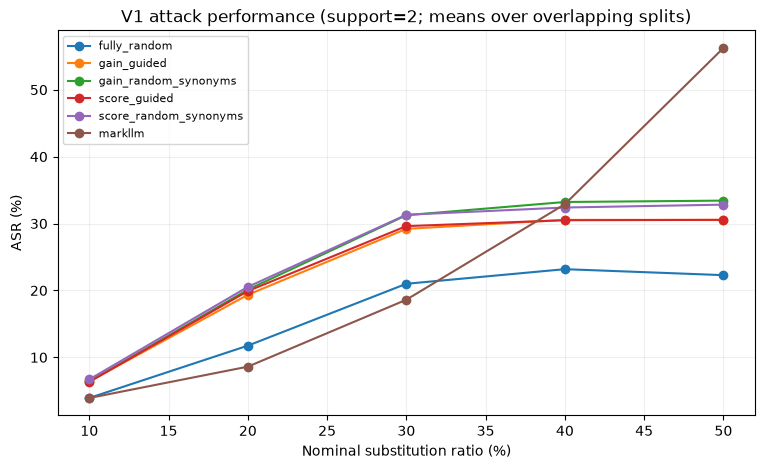

In [5]:
# Optional visualization; if Matplotlib/Pillow is broken, tables remain complete.
try:
    import matplotlib.pyplot as plt
    target = stats[stats.min_support.eq(2)]
    fig, ax = plt.subplots(figsize=(9, 5))
    for method in METHODS:
        p = target[target.method.eq(method)].sort_values("ratio")
        ax.plot(100*p.ratio, 100*p.asr_mean, marker="o", label=method)
    ax.set(xlabel="Nominal substitution ratio (%)", ylabel="ASR (%)",
           title="V1 attack performance (support=2; means over overlapping splits)")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left", fontsize=8)
    plt.show()
except (ImportError, OSError) as exc:
    print("Plot skipped; results tables remain available:", exc)

## 6. Ablation study — position ranking and synonym choice

Paired descriptive differences use the **same split, support, ratio, and test texts**. Positive difference means the first method performs better. Report means, standard deviations across overlapping splits, number of splits with positive difference and ties. They are not formal evidence of generalization.

In [6]:
asr_wide = summary.pivot(index=["min_support", "split_seed", "ratio"], columns="method", values="asr")
comparisons = [
    ("guided positions vs random positions", "score_random_synonyms", "fully_random"),
    ("random vs guided replacement (score ranked)", "score_random_synonyms", "score_guided"),
    ("score vs gain positions (random synonyms)", "score_random_synonyms", "gain_random_synonyms"),
    ("random vs guided replacement (gain ranked)", "gain_random_synonyms", "gain_guided"),
]
contrasts = []
for support in SUPPORTS:
    for ratio in RATIOS:
        group = asr_wide.xs((support, ratio), level=("min_support", "ratio"))
        for label, a, b in comparisons:
            v = 100 * (group[a] - group[b])
            contrasts.append({"min_support":support, "ratio":ratio, "comparison":label,
                              "method_a":a, "method_b":b,
                              "mean_diff_pp":v.mean(), "std_diff_pp":v.std(ddof=1),
                              "a_better_splits":int((v>0).sum()), "ties":int((v==0).sum())})
contrast_table = pd.DataFrame(contrasts)
display(contrast_table[contrast_table.min_support.eq(2)][
    ["ratio", "comparison", "mean_diff_pp", "std_diff_pp", "a_better_splits", "ties"]].round(2))

,ratio,comparison,mean_diff_pp,std_diff_pp,a_better_splits,ties
0,0.1,guided positions vs random positions,2.78,1.62,10,0
1,0.1,random vs guided replacement (score ranked),0.36,1.46,5,1
2,0.1,score vs gain positions (random synonyms),0.31,1.40,4,3
3,0.1,random vs guided replacement (gain ranked),0.00,1.27,7,0
4,0.2,guided positions vs random positions,8.78,3.13,10,0
5,0.2,random vs guided replacement (score ranked),0.63,2.48,5,2
6,0.2,score vs gain positions (random synonyms),0.41,2.44,5,0
7,0.2,random vs guided replacement (gain ranked),0.77,3.05,6,0
8,0.3,guided positions vs random positions,10.32,3.52,10,0
9,0.3,random vs guided replacement (score ranked),1.70,3.26,5,1


## 7. Exact paired McNemar tests + Holm multiplicity correction

**Why McNemar?** Both attacks make binary success/failure decisions on **the same originally detected WM texts**. Define discordant counts:

- \(b\): attack A succeeds, B fails;
- \(c\): attack A fails, B succeeds.

Under McNemar's null of equal marginal success probabilities, conditional on \(b+c\), \(b\) follows \(\mathrm{Binomial}(b+c,1/2)\). We calculate its **exact two-sided** p-value with `scipy.stats.binomtest` (equivalent to exact McNemar). No chi-squared asymptotic approximation is needed.

**Predefined within-this-consolidation comparisons:** at **support=2**, **ratios 0.1, 0.2, 0.3**, split **42**, evaluate three hypotheses: (i) guided positions vs fully random with random synonyms; (ii) random vs score-guided synonym selection at score-ranked positions; (iii) score vs gain ranking, both with random synonyms. **Nine tests**, Holm-corrected together. Chosen *after earlier explorations*: p-values are **exploratory** and can be optimistic. We do **not** pool dependent outcomes from the ten overlapping splits or treat their ASR means as independent samples.

**Interpretation:** an adjusted p-value cannot establish a causal watermark-specific mechanism or independent generalization. Holm (1979) adjusts family-wise error across these nine exploratory tests.

In [7]:
REFERENCE_SEED = 42
REFERENCE_SUPPORT = 2
INFERENTIAL_RATIOS = [0.1, 0.2, 0.3]
TEST_PAIRS = [
    ("guided positions vs random", "score_random_synonyms", "fully_random"),
    ("random vs guided synonyms", "score_random_synonyms", "score_guided"),
    ("score vs gain ranking", "score_random_synonyms", "gain_random_synonyms"),
]


def exact_mcnemar(a_success, b_success):
    a = np.asarray(a_success, dtype=np.int8)
    b = np.asarray(b_success, dtype=np.int8)
    assert a.shape == b.shape and set(np.unique(a)).issubset({0,1}) and set(np.unique(b)).issubset({0,1})
    b_only = int(((a == 1) & (b == 0)).sum())
    c_only = int(((a == 0) & (b == 1)).sum())
    n_discordant = b_only + c_only
    p = float(binomtest(b_only, n_discordant, 0.5, alternative="two-sided").pvalue) if n_discordant else 1.0
    return b_only, c_only, p


def holm_adjust(pvalues):
    """Step-down Holm adjusted p-values (including monotonicity)."""
    p = np.asarray(pvalues, dtype=float)
    assert p.ndim == 1 and np.isfinite(p).all() and ((p>=0)&(p<=1)).all()
    order = np.argsort(p)
    adj_sorted = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[order])
    adjusted = np.empty_like(p)
    adjusted[order] = np.minimum(adj_sorted, 1)
    return adjusted

rows = []
for ratio in INFERENTIAL_RATIOS:
    part = paired[(paired.min_support.eq(REFERENCE_SUPPORT)) &
                  (paired.split_seed.eq(REFERENCE_SEED)) &
                  (np.isclose(paired.ratio,ratio))].sort_values("idx")
    assert 0 < len(part) <= 200
    for name, a, b in TEST_PAIRS:
        av = part[f"success_{a}"].to_numpy(dtype=int)
        bv = part[f"success_{b}"].to_numpy(dtype=int)
        b_only, c_only, pvalue = exact_mcnemar(av, bv)
        rows.append({"split_seed": REFERENCE_SEED, "min_support": REFERENCE_SUPPORT,
                     "ratio": ratio, "comparison": name, "method_a":a, "method_b":b,
                     "n":len(part), "asr_a":av.mean(), "asr_b":bv.mean(),
                     "difference_pp":100*(av.mean()-bv.mean()),
                     "A_only_success": b_only, "B_only_success": c_only,
                     "discordant":b_only+c_only, "p_raw":pvalue})
mcnemar_table = pd.DataFrame(rows)
mcnemar_table["p_holm"] = holm_adjust(mcnemar_table.p_raw.to_numpy())
mcnemar_table["holm_below_0_05"] = mcnemar_table.p_holm < 0.05
display(mcnemar_table[["ratio", "comparison", "n", "asr_a", "asr_b", "difference_pp",
                       "A_only_success", "B_only_success", "discordant", "p_raw", "p_holm",
                       "holm_below_0_05"]].round(5))
print("All p-values exploratory; overlapping splits not pooled; tested split 42 only.")

,ratio,comparison,n,asr_a,asr_b,difference_pp,A_only_success,B_only_success,discordant,p_raw,p_holm,holm_below_0_05
0,0.1,guided positions vs random,195,0.06154,0.03590,2.56410,9,4,13,0.26685,1.00000,False
1,0.1,random vs guided synonyms,195,0.06154,0.05641,0.51282,2,1,3,1.00000,1.00000,False
2,0.1,score vs gain ranking,195,0.06154,0.07179,-1.02564,2,4,6,0.68750,1.00000,False
3,0.2,guided positions vs random,195,0.23077,0.14359,8.71795,25,8,33,0.00455,0.04096,True
4,0.2,random vs guided synonyms,195,0.23077,0.20000,3.07692,14,8,22,0.28628,1.00000,False
5,0.2,score vs gain ranking,195,0.23077,0.18974,4.10256,17,9,26,0.16864,1.00000,False
6,0.3,guided positions vs random,195,0.25641,0.16923,8.71795,30,13,43,0.01372,0.10975,False
7,0.3,random vs guided synonyms,195,0.25641,0.26154,-0.51282,13,14,27,1.00000,1.00000,False
8,0.3,score vs gain ranking,195,0.25641,0.29231,-3.58974,12,19,31,0.28104,1.00000,False


All p-values exploratory; overlapping splits not pooled; tested split 42 only.


## 8. Stability over splits and dataset breakdown

Averages and standard deviations help assess variability **descriptively**. The ten splits overlap, so a standard error obtained by treating them as ten independent repetitions would be misleading. Dataset breakdown uses only originally detected WM completions.

In [8]:
focus = stats[stats.min_support.eq(2) & stats.method.isin([
    "fully_random", "score_guided", "score_random_synonyms", "gain_random_synonyms", "markllm"])]
display(focus[["ratio", "method", "asr_mean", "asr_std", "edit_mean"]].sort_values(["ratio", "method"]).round(4))

# Mean dataset-specific ASRs over the ten overlapping splits, at 30% nominal budget.
dataset_view = (dataset[dataset.min_support.eq(2) & np.isclose(dataset.ratio, 0.3)]
    .groupby(["dataset", "method"], as_index=False)
    .agg(mean_asr=("asr", "mean"), std_asr=("asr", "std"), mean_eligible_n=("eligible_n", "mean")))
display(dataset_view.round(4))

,ratio,method,asr_mean,asr_std,edit_mean
0,0.1,fully_random,0.0393,0.0221,0.0999
2,0.1,gain_random_synonyms,0.0640,0.0148,0.0999
3,0.1,markllm,0.0392,0.0171,NaN
4,0.1,score_guided,0.0634,0.0166,0.0999
5,0.1,score_random_synonyms,0.0671,0.0172,0.0999
6,0.2,fully_random,0.1175,0.0246,0.1930
8,0.2,gain_random_synonyms,0.2012,0.0306,0.1930
9,0.2,markllm,0.0861,0.0163,NaN
10,0.2,score_guided,0.1991,0.0279,0.1930
11,0.2,score_random_synonyms,0.2053,0.0353,0.1930


,dataset,method,mean_asr,std_asr,mean_eligible_n
0,2-1_longform_qa,fully_random,0.1733,0.0561,65.8
1,2-1_longform_qa,gain_guided,0.2734,0.0505,65.8
2,2-1_longform_qa,gain_random_synonyms,0.2963,0.0520,65.8
3,2-1_longform_qa,markllm,0.1551,0.0440,65.8
4,2-1_longform_qa,score_guided,0.2795,0.0564,65.8
5,2-1_longform_qa,score_random_synonyms,0.2980,0.0683,65.8
6,2-2_finance_qa,fully_random,0.2605,0.0413,66.4
7,2-2_finance_qa,gain_guided,0.3539,0.0528,66.4
8,2-2_finance_qa,gain_random_synonyms,0.3795,0.0417,66.4
9,2-2_finance_qa,markllm,0.1355,0.0345,66.4


## 9. What we can and cannot conclude

**Supported descriptively by the completed experiment:**

1. Guided positions with random WordNet synonyms tend to outperform fully random positions under matched custom-attack edit counts.
2. Random WordNet synonyms often work as well as, or better than, frequency-score-guided synonyms.
3. Ranking by WM score and by best possible score gain yields similar results; neither is a clearly established winner.
4. Smaller `MIN_SUPPORT` expands eligibility and effective edit coverage. Improvements at high nominal ratios cannot be attributed purely to better statistical estimates.

**Limitations:**

- The score is a word-occurrence WM/NoWM log-ratio, **not** a direct estimate of token-level watermark greenlist status.
- WordNet single-word substitution can change meaning; **semantic preservation has not been evaluated in V1**.
- High nominal budgets saturate; at `MIN_SUPPORT=2` only roughly one-quarter of word occurrences can be substituted. Actual edits are essential for interpretation.
- MarkLLM's **nominal** ratio cannot be assumed equal to its *effective* ratio; avoid declaring matched-budget superiority over MarkLLM.
- Split overlap plus exploratory parameter selection prevent confirmatory p-value interpretations.
- Our text data are drawn from three WaterBench datasets; performance elsewhere is unknown.

**Motivation for V2:** examine contextual sequence information (word bigrams, then LLaDA-token bigrams) to ask whether learned sequence patterns can improve the **selection of positions and/or replacements**.

## 10. Export final reproducible report tables

Writes **derived CSVs only** under `results/attacks/stealing_guided_v1_final/`. The notebook reads prior completed checkpoints; it does not overwrite notebook-10/11 results.

In [9]:
exports = {
    "v1_asr_by_configuration.csv": stats,
    "v1_position_synonym_ablations.csv": contrast_table,
    "v1_exact_mcnemar_holm.csv": mcnemar_table,
    "v1_dataset_breakdown.csv": dataset_view,
}
for filename, table in exports.items():
    table.to_csv(FINAL / filename, index=False)

manifest = {
    "notebook": "12_stealing_guided_v1_final.ipynb",
    "protocol": "exploratory; 10 overlapping stratified 400/200 splits; McNemar on reference split 42",
    "mcnemar": "exact two-sided; Holm over 9 comparisons; selected after exploratory experiments",
    "inputs": {str(path.relative_to(ROOT)): sha256(path) for path in FILES.values()},
    "supports": SUPPORTS, "ratios": RATIOS, "seeds": SEEDS,
    "outputs": list(exports),
    "markllm_effective_edits_verified": False,
    "semantic_quality_measured": False,
}
(FINAL / "v1_report_manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf8")
print("Saved final tables and provenance manifest to:", FINAL)
for name in [*exports, "v1_report_manifest.json"]:
    print(" -", name)

Saved final tables and provenance manifest to: /Users/paulmicheli/Desktop/Unine/MA1/Trustworthy/Trustworhty_AI_Watermarking/results/attacks/stealing_guided_v1_final
 - v1_asr_by_configuration.csv
 - v1_position_synonym_ablations.csv
 - v1_exact_mcnemar_holm.csv
 - v1_dataset_breakdown.csv
 - v1_report_manifest.json


## References and definitions

- **McNemar, Q. (1947).** *Note on the sampling error of the difference between correlated proportions or percentages.* Psychometrika 12, 153–157. https://doi.org/10.1007/BF02295996
- **Holm, S. (1979).** *A Simple Sequentially Rejective Multiple Test Procedure.* Scandinavian Journal of Statistics 6(2), 65–70.
- **Exact McNemar implementation:** conditional two-sided binomial test (`scipy.stats.binomtest`); equivalent to the exact McNemar test for discordant pairs.
- **ASR:** fraction of *originally detected* WM completions rendered non-detected after an attack.
- **Related code:** notebooks 10/11 preserve attack generation and detector checkpoints. This clean consolidation notebook is the V1 entry point for reading results, not a self-contained regeneration of expensive model outputs.

**Final reporting note:** do not describe the selected strategy as independently validated or claim a statistically significant overall superiority unless supported by the explicitly exploratory paired tests and their multiple-testing correction.